In [1]:
from pathlib import Path
from getpass import getpass

import numpy as np
import pandas as pd
import scipy.sparse as sp
import networkx as nx
import matplotlib.pyplot as plt

from neo4j import GraphDatabase

In [2]:
# 1. KONFIGURASI

URI = "bolt://127.0.0.1:7687"
USERNAME = "neo4j"
PASSWORD = getpass("Masukkan password Neo4j: ")

OUTPUT_DIR = Path("data/processed")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

In [3]:
# 2. AMBIL PASANGAN USER-ITEM DARI P1

QUERY = """
MATCH (v:Visitor)-[r]->(i:Item)
WHERE r.fold = 'P1'
RETURN DISTINCT
    v.visitorId AS user_id,
    i.itemId AS item_id
ORDER BY user_id, item_id
"""

driver = GraphDatabase.driver(
    URI,
    auth=(USERNAME, PASSWORD)
)

try:
    with driver.session(database="neo4j") as session:
        result = session.run(QUERY)

        # Setiap pasangan user-item hanya dicatat sekali.
        pairs = [
            (record["user_id"], record["item_id"])
            for record in result
        ]
finally:
    driver.close()

if not pairs:
    raise ValueError("Tidak ditemukan pasangan user-item pada P1.")

print("Jumlah pasangan user-item unik:", f"{len(pairs):,}")

Jumlah pasangan user-item unik: 266,342


In [4]:
# 3. BENTUK MATRIKS VSM BINER

user_ids = sorted({user_id for user_id, _ in pairs})
item_ids = sorted({item_id for _, item_id in pairs})

user_to_idx = {
    user_id: idx for idx, user_id in enumerate(user_ids)
}
item_to_idx = {
    item_id: idx for idx, item_id in enumerate(item_ids)
}

row_indices = [
    user_to_idx[user_id]
    for user_id, item_id in pairs
]
col_indices = [
    item_to_idx[item_id]
    for user_id, item_id in pairs
]

values = np.ones(len(pairs), dtype=np.uint8)

# Sparse matrix: baris = User, kolom = Item
VSM_user = sp.csr_matrix(
    (values, (row_indices, col_indices)),
    shape=(len(user_ids), len(item_ids)),
    dtype=np.uint8
)

# Simpan matriks dan daftar ID agar bisa digunakan kembali.
sp.save_npz(
    OUTPUT_DIR / "VSM_user_P1.npz",
    VSM_user
)

pd.Series(user_ids, name="user_id").to_csv(
    OUTPUT_DIR / "VSM_user_ids_P1.csv",
    index=False
)

pd.Series(item_ids, name="item_id").to_csv(
    OUTPUT_DIR / "VSM_item_ids_P1.csv",
    index=False
)

In [5]:
# 4. KARAKTERISTIK VSM

total_cells = VSM_user.shape[0] * VSM_user.shape[1]
nonzero = VSM_user.nnz
density = nonzero / total_cells
sparsity = 1 - density

print("\n===== KARAKTERISTIK VSM USER P1 =====")
print("Jumlah User       :", f"{VSM_user.shape[0]:,}")
print("Jumlah Item       :", f"{VSM_user.shape[1]:,}")
print("Shape matriks     :", VSM_user.shape)
print("Jumlah interaksi  :", f"{nonzero:,}")
print("Density           :", f"{density:.8%}")
print("Sparsity          :", f"{sparsity:.8%}")
print("Ukuran matriks    :", f"{VSM_user.data.nbytes:,}", "byte untuk data nonzero")

print("\nFile matriks disimpan di:")
print((OUTPUT_DIR / "VSM_user_P1.npz").resolve())


===== KARAKTERISTIK VSM USER P1 =====
Jumlah User       : 185,205
Jumlah Item       : 87,308
Shape matriks     : (185205, 87308)
Jumlah interaksi  : 266,342
Density           : 0.00164715%
Sparsity          : 99.99835285%
Ukuran matriks    : 266,342 byte untuk data nonzero

File matriks disimpan di:
C:\Users\ADVAN\UTS-GSD-Rebriane-24031554039\data\processed\VSM_user_P1.npz



===== GRAF SAMPEL NETWORKX =====
Jumlah node sampel : 45
Jumlah edge sampel : 25


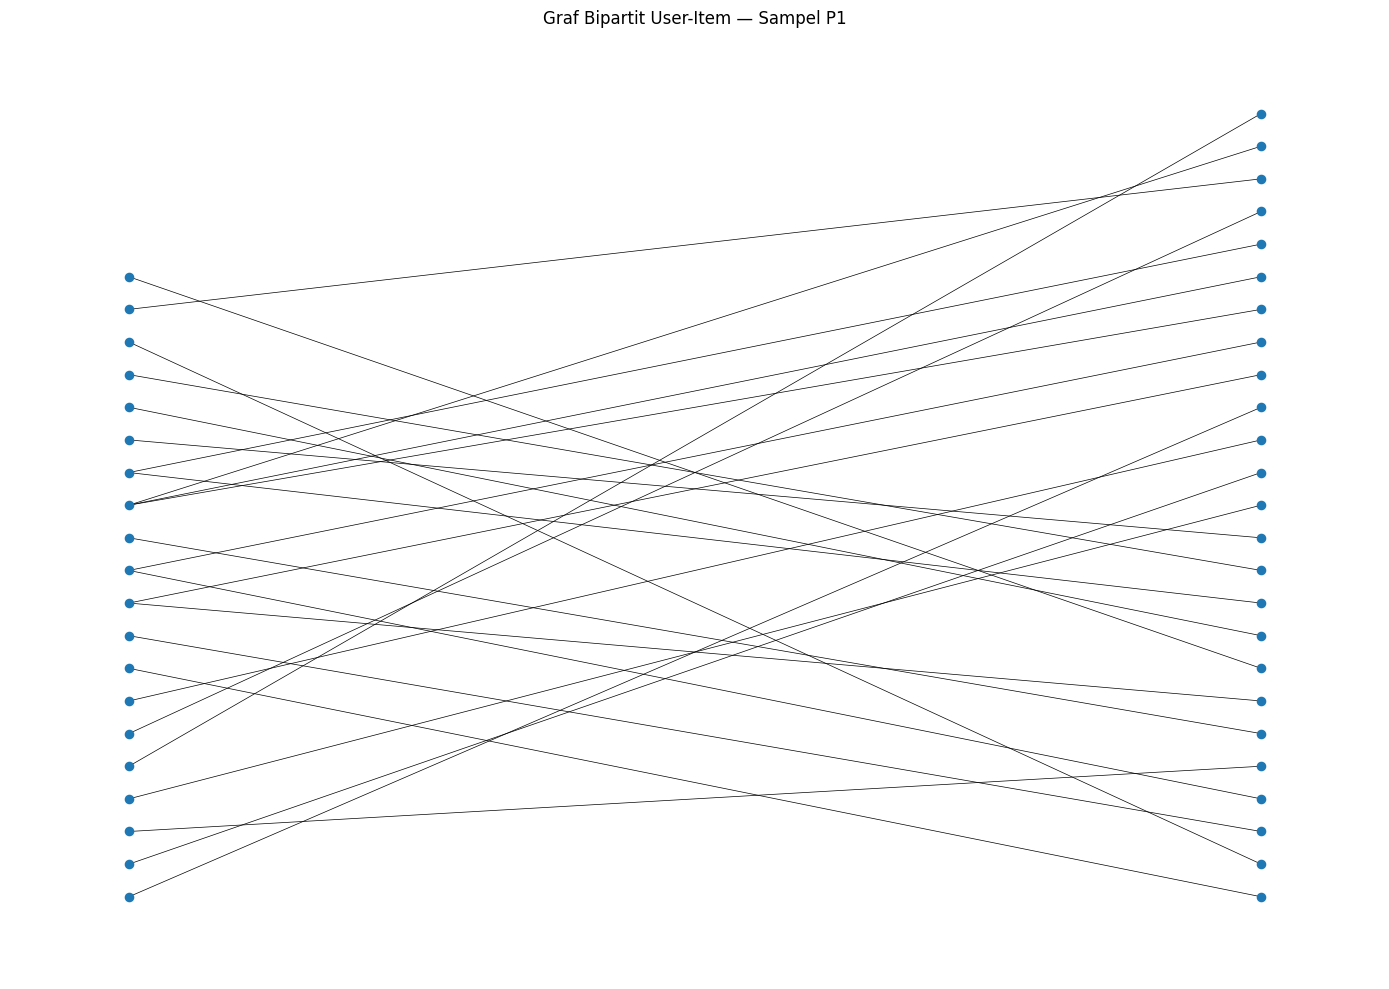

In [9]:
# 5. VISUALISASI NETWORKX DARI SAMPEL KECIL

# Ambil maksimal 20 user pertama untuk visualisasi.
# Ini hanya sampel visual, bukan seluruh graf.
sample_size = min(20, len(user_ids))
sample_user_indices = list(range(sample_size))

# Ambil matriks untuk 20 user pertama
sample_matrix = VSM_user[sample_user_indices, :]

# Indeks kolom item yang benar-benar berinteraksi
sample_item_indices = np.unique(sample_matrix.indices)

# Buat graf bipartit
G = nx.Graph()

sample_user_names = [user_ids[idx] for idx in sample_user_indices]
sample_item_names = [item_ids[idx] for idx in sample_item_indices]

G.add_nodes_from(
    [f"U:{user_id}" for user_id in sample_user_names],
    bipartite="user"
)
G.add_nodes_from(
    [f"I:{item_id}" for item_id in sample_item_names],
    bipartite="item"
)

# Tambahkan edge berdasarkan indeks kolom asli matriks
coo = sample_matrix.tocoo()

for row, col in zip(coo.row, coo.col):
    user_id = user_ids[sample_user_indices[row]]
    item_id = item_ids[col]  # Perbaikan: gunakan indeks kolom asli
    G.add_edge(f"U:{user_id}", f"I:{item_id}")

print("\n===== GRAF SAMPEL NETWORKX =====")
print("Jumlah node sampel :", G.number_of_nodes())
print("Jumlah edge sampel :", G.number_of_edges())

user_nodes = [
    n for n, d in G.nodes(data=True)
    if d["bipartite"] == "user"
]
item_nodes = [
    n for n, d in G.nodes(data=True)
    if d["bipartite"] == "item"
]

pos = {}

for idx, node in enumerate(user_nodes):
    pos[node] = (0, idx)

for idx, node in enumerate(item_nodes):
    pos[node] = (1, idx)

plt.figure(figsize=(14, 10))
nx.draw_networkx(
    G,
    pos=pos,
    with_labels=False,
    node_size=35,
    width=0.5
)

plt.title("Graf Bipartit User-Item — Sampel P1")
plt.axis("off")
plt.tight_layout()

output_plot = OUTPUT_DIR / "networkx_user_item_P1.png"
plt.savefig(output_plot, dpi=200, bbox_inches="tight")
plt.show()